In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import shap

CSV_PATH = "1st device.csv"   # নিজের পাথ অনুযায়ী পরিবর্তন করুন

df = pd.read_csv(CSV_PATH)
df.head()


,Thickness,Defect Density,Acceptor Density,Electron Affinity,Band Gap,VB,CB,PCE,Voc,JSC,FF
0,0.7,1.000000e+11,1.000000e+20,3.88,1.48,1.600000e+18,8.330000e+18,24.7,1.23,22.4,89.9
1,0.7,1.000000e+11,1.000000e+20,3.88,1.48,1.600000e+18,8.330000e+19,22.9,1.17,22.1,88.8
2,0.7,1.000000e+11,1.000000e+20,3.88,1.48,1.600000e+18,8.330000e+20,18.1,1.11,19.6,83.1
3,0.7,1.000000e+11,1.000000e+20,3.88,1.48,1.600000e+19,8.330000e+18,27.6,1.20,25.7,89.7
4,0.7,1.000000e+11,1.000000e+20,3.88,1.48,1.600000e+19,8.330000e+19,25.9,1.14,25.5,89.0


In [5]:
feature_cols = ['Thickness', 'Defect Density', 'Acceptor Density',
                'Electron Affinity', 'Band Gap', 'VB', 'CB']
targets = ['PCE', 'Voc', 'JSC', 'FF']

X = df[feature_cols]
print("Total samples:", len(df))
print("Features:", feature_cols)


Total samples: 2187
Features: ['Thickness', 'Defect Density', 'Acceptor Density', 'Electron Affinity', 'Band Gap', 'VB', 'CB']


In [6]:
models = {}
predictions = {}   # y_test, y_pred প্রতিটি target এর জন্য
r2_scores = {}

for t in targets:
    y = df[t]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    model = RandomForestRegressor(n_estimators=300, random_state=42)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    models[t] = model
    predictions[t] = (y_test.values, y_pred)
    r2_scores[t] = r2_score(y_test, y_pred)

for t in targets:
    print(f"{t}: R² = {r2_scores[t]:.4f}")

print(f"\nAverage R² = {np.mean(list(r2_scores.values())):.4f}")


PCE: R² = 0.9991
Voc: R² = 0.9999
JSC: R² = 0.9998
FF: R² = 0.9998

Average R² = 0.9997


/var/folders/wg/j8__hnzd1_z6_42l1cqxkqhw0000gn/T/ipykernel_4807/2778009902.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(importances.index, rotation=30, ha='right')


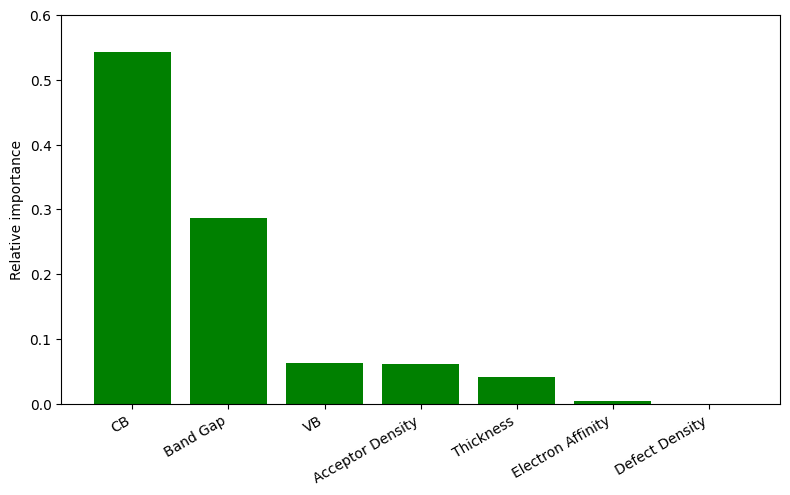

CB                   0.542799
Band Gap             0.286926
VB                   0.062415
Acceptor Density     0.061774
Thickness            0.041416
Electron Affinity    0.004264
Defect Density       0.000405
dtype: float64


In [18]:
pce_model = models['PCE']
importances = pd.Series(pce_model.feature_importances_, index=feature_cols)
importances = importances.sort_values(ascending=False)

# পেপারের নাম অনুযায়ী কিছু ফিচারের label ম্যাপ (ইচ্ছা করলে বদলাতে পারেন)
label_map = {
    'Acceptor Density': 'Acceptor Density',
    'Defect Density': 'Defect Density',
    'CB': 'CB',
    'Electron Affinity': 'Electron Affinity',
    'VB': 'VB',
    'Thickness': 'Thickness',
    'Band Gap': 'Band Gap'
}

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(importances.index, importances.values, color='green')
ax.set_ylabel('Relative importance')
ax.set_xticklabels(importances.index, rotation=30, ha='right')
plt.tight_layout()
plt.ylim(0,0.6)
plt.savefig('Fig11_feature_importance.png', dpi=600)
plt.show()

print(importances)


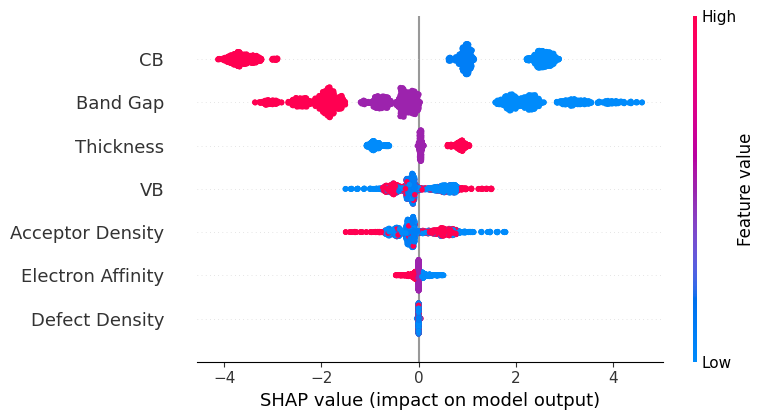

In [19]:
explainer = shap.TreeExplainer(pce_model)
shap_values = explainer.shap_values(X)

shap.summary_plot(shap_values, X, feature_names=feature_cols, show=False)
plt.tight_layout()
plt.savefig('Fig12_shap_summary.png', dpi=600, bbox_inches='tight')
plt.show()


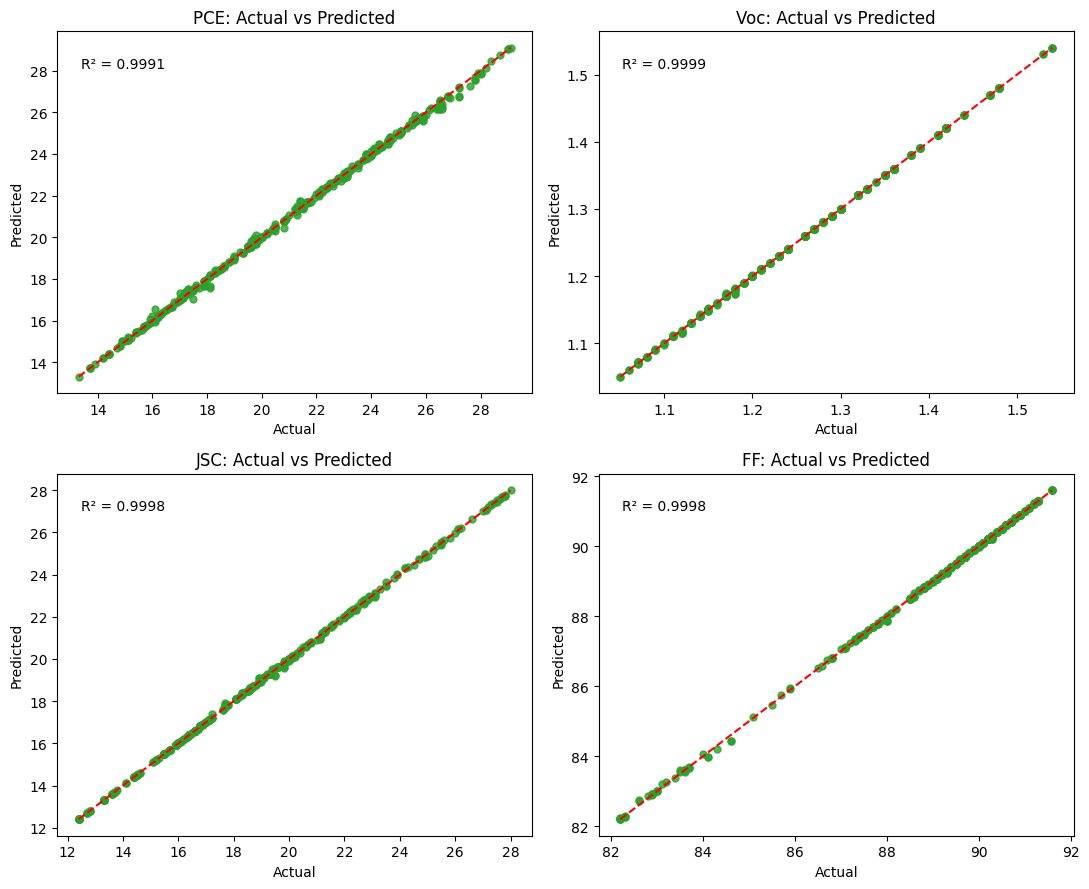

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
titles = {'PCE': 'PCE: Actual vs Predicted',
          'Voc': 'Voc: Actual vs Predicted',
          'JSC': 'JSC: Actual vs Predicted',
          'FF': 'FF: Actual vs Predicted'}

for ax, t in zip(axes.flat, targets):
    y_test, y_pred = predictions[t]
    ax.scatter(y_test, y_pred, color='tab:green', s=25, alpha=0.8)
    lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
    ax.plot(lims, lims, 'r--', linewidth=1.5)
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')
    ax.set_title(titles[t])
    ax.text(0.05, 0.9, f"R² = {r2_scores[t]:.4f}", transform=ax.transAxes)

plt.tight_layout()
plt.savefig('Fig13_actual_vs_predicted.png', dpi=600)
plt.show()
